# WellbeingIQ · Notebook 2: Exploratory Data Analysis (EDA) & Business Insights
**Input:** `WellbeingIQ_cleaned.csv` (output of Notebook 1) · **Target:** `Wellness_Category` (At-Risk / Moderate / Good)

> **Data note:** the dataset is **synthetic** (simulated, no real students). Patterns below describe the simulated data and are used to build and test the pipeline. They are not findings about real students. Not a medical tool.

**Questions this notebook answers**
1. How are the habits and the target distributed?
2. Which habits move with wellbeing, and how strongly?
3. Where does risk jump (thresholds), and which combinations are most risky?
4. Do demographics or platform matter?
5. What does this mean for modeling and for the wellness guidance we will generate?

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns',40)
df = pd.read_csv('WellbeingIQ_cleaned.csv')
ORDER = ['At-Risk','Moderate','Good']; PAL = {'At-Risk':'#C00000','Moderate':'#F4B183','Good':'#548235'}
df['Wellness_Category'] = pd.Categorical(df.Wellness_Category, ORDER, ordered=True)
df['at_risk'] = (df.Wellness_Category=='At-Risk').astype(int)
print(df.shape); df.head(3)

(6000, 29)


,Student_ID,Age,Gender,Country,Academic_Level,Residence,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Total_Screen_Time_Hours,Gaming_Hours,Daily_Unlocks,Notifications_Per_Day,Late_Night_Usage_Hours,Study_Hours,Sleep_Hours_Per_Night,Sleep_Quality,Caffeine_Cups_Per_Day,Physical_Activity_Hours,Days_Offline_Per_Month,Social_Support_Score,Academic_Pressure,Academic_Performance_Pct,Conflicts_Over_Social_Media,Addiction_Score,Stress_Level,Mental_Health_Score,Wellness_Category,at_risk
0,S00001,21.0,Female,Indonesia,Undergraduate,Hostel,Instagram,Entertainment,5.4,7.4,1.0,97,105,1.6,6.5,5.8,2.0,4.0,0.2,2.0,5.0,6,85.7,1,7,High,4.5,At-Risk,1
1,S00002,22.0,Female,Indonesia,Undergraduate,Hostel,WhatsApp,Mixed,3.2,7.5,1.9,65,149,0.0,2.5,7.8,3.0,NaN,1.6,3.0,9.0,4,77.0,2,5,Low,9.0,Good,0
2,S00003,18.0,Male,Nigeria,High School,Rented room,YouTube,Social connection,4.5,8.4,1.8,122,121,1.9,4.3,5.1,1.0,4.0,0.7,2.0,4.0,6,59.8,3,6,High,4.0,At-Risk,1


## 1. Distributions

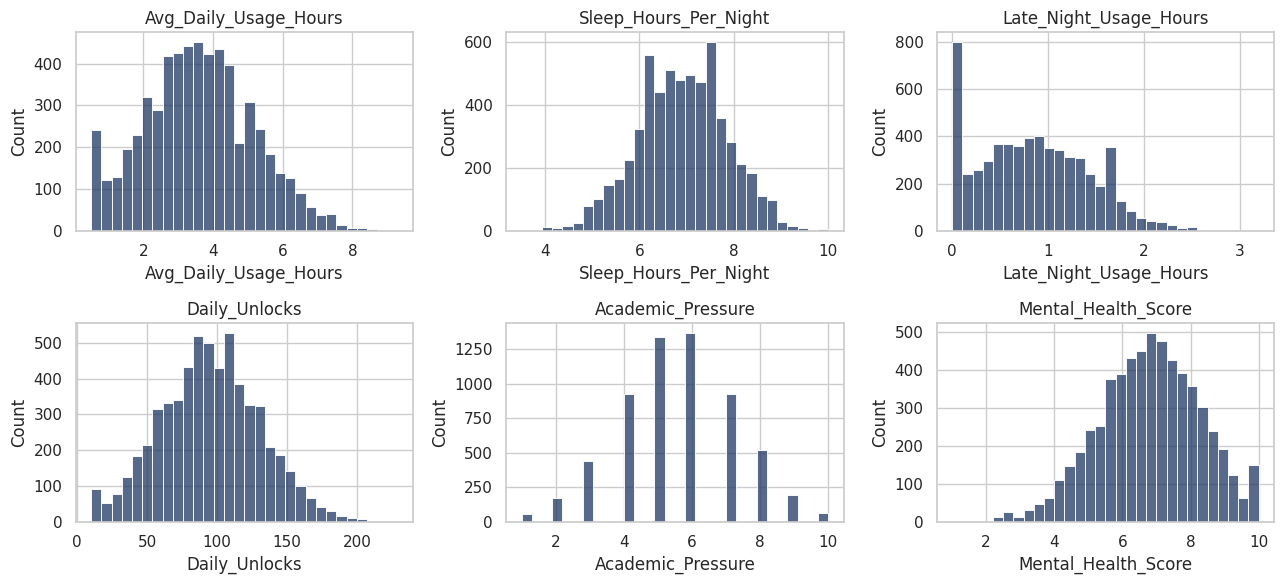

,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Late_Night_Usage_Hours,Daily_Unlocks,Academic_Pressure,Mental_Health_Score
mean,3.59,6.90,0.86,95.26,5.56,6.74
median,3.60,6.90,0.80,95.00,6.00,6.80
std,1.56,0.94,0.57,35.79,1.72,1.50
skew,0.15,-0.07,0.39,0.09,0.00,-0.20


In [2]:
cols = ['Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Late_Night_Usage_Hours','Daily_Unlocks','Academic_Pressure','Mental_Health_Score']
fig,ax = plt.subplots(2,3,figsize=(13,6))
for a,c in zip(ax.ravel(),cols): sns.histplot(df[c],bins=30,ax=a,color='#1F3864'); a.set_title(c)
plt.tight_layout(); plt.show()
df[cols].agg(['mean','median','std','skew']).round(2)

**Reading:** usage, late-night use and unlocks are right-skewed (a minority are very heavy users). Sleep and the score are close to bell-shaped. Mild skew only, so tree models and logistic regression with scaling will cope; no need to drop rows.

## 2. Habits by wellness category

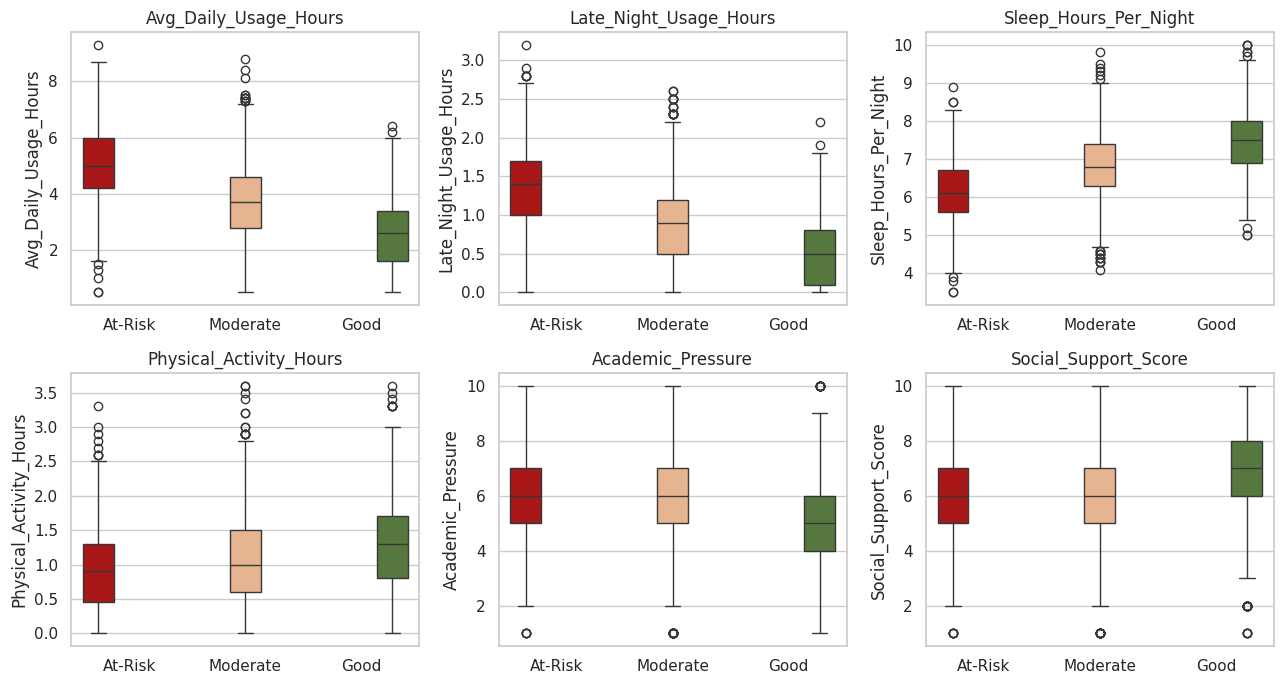

,Avg_Daily_Usage_Hours,Late_Night_Usage_Hours,Sleep_Hours_Per_Night,Physical_Activity_Hours,Academic_Pressure,Social_Support_Score
Wellness_Category,,,,,,
At-Risk,5.05,1.38,6.13,0.92,6.06,5.73
Moderate,3.72,0.89,6.81,1.07,5.63,6.22
Good,2.56,0.51,7.48,1.29,5.14,6.72


In [3]:
cols = ['Avg_Daily_Usage_Hours','Late_Night_Usage_Hours','Sleep_Hours_Per_Night','Physical_Activity_Hours','Academic_Pressure','Social_Support_Score']
fig,ax = plt.subplots(2,3,figsize=(13,7))
for a,c in zip(ax.ravel(),cols): sns.boxplot(data=df,x='Wellness_Category',y=c,order=ORDER,palette=PAL,ax=a,hue='Wellness_Category',legend=False); a.set_title(c); a.set_xlabel('')
plt.tight_layout(); plt.show()
df.groupby('Wellness_Category',observed=True)[cols].mean().round(2)

## 3. Correlation with the wellbeing score

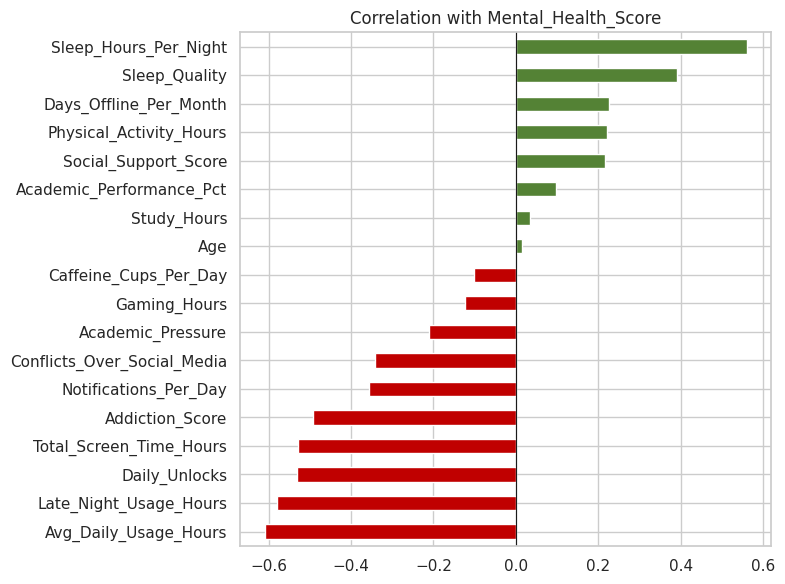

,Avg_Daily_Usage_Hours,Late_Night_Usage_Hours,Daily_Unlocks,Total_Screen_Time_Hours,Addiction_Score,Notifications_Per_Day,Conflicts_Over_Social_Media,Academic_Pressure,Gaming_Hours,Caffeine_Cups_Per_Day,Age,Study_Hours,Academic_Performance_Pct,Social_Support_Score,Physical_Activity_Hours,Days_Offline_Per_Month,Sleep_Quality,Sleep_Hours_Per_Night
correlation,-0.61,-0.58,-0.53,-0.53,-0.49,-0.36,-0.34,-0.21,-0.12,-0.1,0.02,0.03,0.1,0.22,0.22,0.23,0.39,0.56


In [4]:
num = df.select_dtypes('number').drop(columns=['at_risk'])
corr = num.corr()['Mental_Health_Score'].drop('Mental_Health_Score').sort_values()
plt.figure(figsize=(8,6)); corr.plot.barh(color=['#C00000' if v<0 else '#548235' for v in corr]); plt.title('Correlation with Mental_Health_Score'); plt.axvline(0,color='k',lw=.8); plt.tight_layout(); plt.show()
corr.round(2).to_frame('correlation').T

**Reading:** usage, late-night use, unlocks and sleep hours have the strongest links (|r| about 0.5 to 0.6). Sleep quality, days offline, activity and social support are moderate. Study hours and age show almost no linear link.

### Multicollinearity check (usage-related columns)

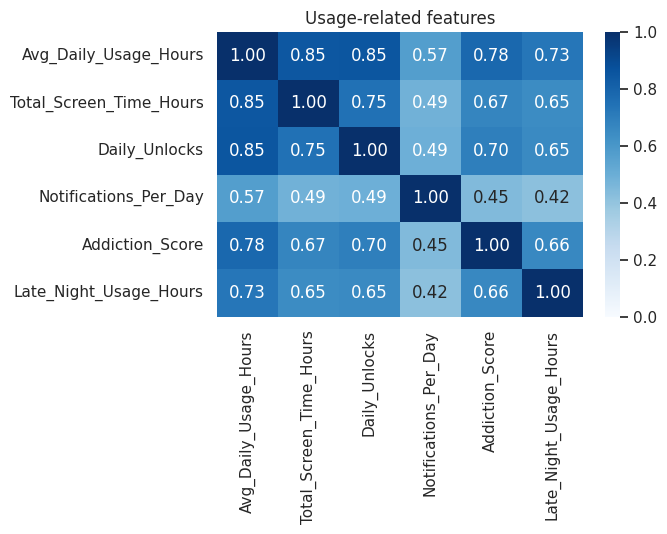

In [5]:
u = ['Avg_Daily_Usage_Hours','Total_Screen_Time_Hours','Daily_Unlocks','Notifications_Per_Day','Addiction_Score','Late_Night_Usage_Hours']
plt.figure(figsize=(7,5.5)); sns.heatmap(df[u].corr(),annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1); plt.title('Usage-related features'); plt.tight_layout(); plt.show()

**Reading:** usage, total screen time, unlocks and addiction score overlap strongly (r up to 0.85). Tree models handle this; for Logistic Regression we should regularize and be careful interpreting individual coefficients. SHAP will also split credit among overlapping features.

## 4. Where does risk jump?

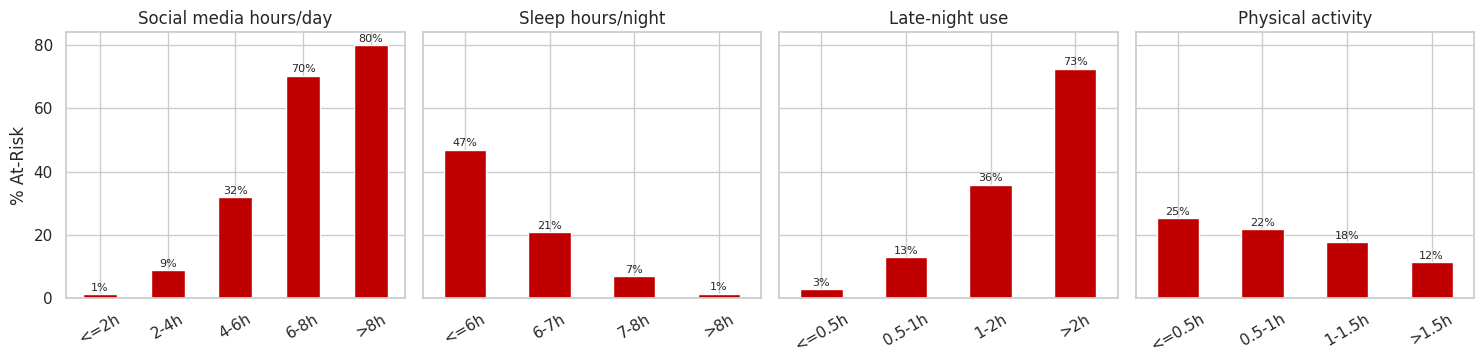

In [6]:
def band(col,bins,labels=None): return pd.cut(df[col],bins,labels=labels)
df['usage_band']=band('Avg_Daily_Usage_Hours',[0,2,4,6,8,20],['<=2h','2-4h','4-6h','6-8h','>8h'])
df['sleep_band']=band('Sleep_Hours_Per_Night',[0,6,7,8,12],['<=6h','6-7h','7-8h','>8h'])
df['late_band']=band('Late_Night_Usage_Hours',[-.1,.5,1,2,5],['<=0.5h','0.5-1h','1-2h','>2h'])
df['act_band']=band('Physical_Activity_Hours',[-.1,.5,1,1.5,5],['<=0.5h','0.5-1h','1-1.5h','>1.5h'])
fig,ax = plt.subplots(1,4,figsize=(15,3.8),sharey=True)
for a,(b,t) in zip(ax,[('usage_band','Social media hours/day'),('sleep_band','Sleep hours/night'),('late_band','Late-night use'),('act_band','Physical activity')]):
    r = df.groupby(b,observed=True).at_risk.mean()*100; r.plot.bar(ax=a,color='#C00000',rot=30); a.set_title(t); a.set_xlabel(''); a.set_ylabel('% At-Risk')
    for i,v in enumerate(r): a.text(i,v+1,f'{v:.0f}%',ha='center',fontsize=8)
plt.tight_layout(); plt.show()

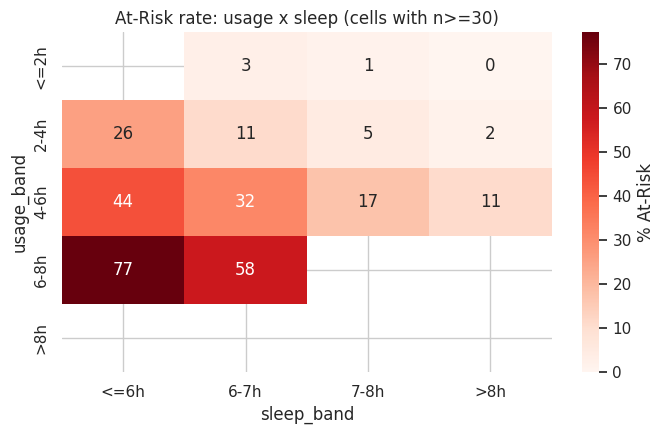

Usage >= 6h AND sleep < 6.5h: 346 students, At-Risk rate 71% vs overall 19%


In [7]:
piv = df.pivot_table(index='usage_band',columns='sleep_band',values='at_risk',aggfunc='mean',observed=True)*100
cnt = df.pivot_table(index='usage_band',columns='sleep_band',values='at_risk',aggfunc='size',observed=True)
plt.figure(figsize=(7,4.5)); sns.heatmap(piv.where(cnt>=30),annot=True,fmt='.0f',cmap='Reds',cbar_kws={'label':'% At-Risk'}); plt.title('At-Risk rate: usage x sleep (cells with n>=30)'); plt.tight_layout(); plt.show()
hr = df[(df.Avg_Daily_Usage_Hours>=6)&(df.Sleep_Hours_Per_Night<6.5)]
print(f'Usage >= 6h AND sleep < 6.5h: {len(hr)} students, At-Risk rate {hr.at_risk.mean():.0%} vs overall {df.at_risk.mean():.0%}')

## 5. Do demographics or platform matter?

,Feature,Lowest group mean,Highest group mean,Kruskal-Wallis p
0,Country,6.67,6.84,0.536
1,Gender,6.67,6.75,0.617
2,Most_Used_Platform,6.68,6.84,0.504
3,Purpose_Of_Use,6.71,6.81,0.484
4,Academic_Level,6.68,6.76,0.605
5,Residence,6.73,6.75,0.842


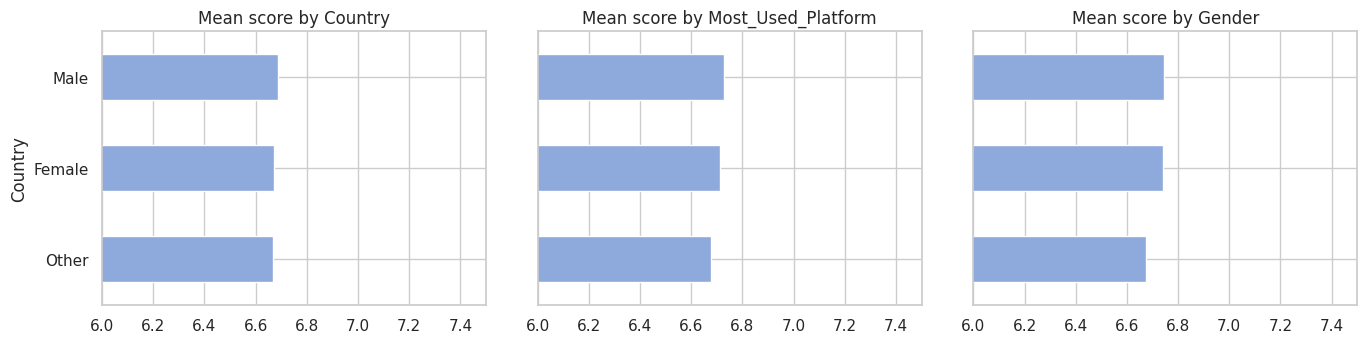

In [8]:
rows=[]
for c in ['Country','Gender','Most_Used_Platform','Purpose_Of_Use','Academic_Level','Residence']:
    g=[x.Mental_Health_Score.values for _,x in df.groupby(c)]
    m=df.groupby(c).Mental_Health_Score.mean()
    rows.append({'Feature':c,'Lowest group mean':round(m.min(),2),'Highest group mean':round(m.max(),2),'Kruskal-Wallis p':round(stats.kruskal(*g).pvalue,3)})
display(pd.DataFrame(rows))
fig,ax=plt.subplots(1,3,figsize=(14,3.6),sharey=True)
for a,c in zip(ax,['Country','Most_Used_Platform','Gender']):
    df.groupby(c).Mental_Health_Score.mean().sort_values().plot.barh(ax=a,color='#8EA9DB'); a.set_title('Mean score by '+c); a.set_xlim(6,7.5)
plt.tight_layout(); plt.show()

**Reading:** differences between countries, genders, platforms, purposes, levels and residences are tiny and not statistically significant (all p above 0.4). In this dataset, **how much and when** students use their phone matters, **which app or which group** does not. We will confirm with SHAP, and avoid making claims about groups.

## 6. Stress level vs risk (information only)

In [9]:
t = df.groupby('Stress_Level').at_risk.mean().reindex(['Low','Medium','High','Very High'])*100
display(t.round(0).to_frame('% At-Risk'))

,% At-Risk
Stress_Level,
Low,1.0
Medium,8.0
High,34.0
Very High,75.0


`Stress_Level` tracks risk closely, which is exactly why it is **excluded from the model features**: in the simulation it was built partly from the wellbeing score, so using it would leak the answer.

## 7. Business insights (from this synthetic dataset)
1. **Usage is the strongest lever.** At-Risk share rises from about 1% (up to 2h/day) to 9% (2 to 4h), 32% (4 to 6h) and 70% (6 to 8h). Risk climbs steeply beyond roughly 4 hours a day.
2. **Sleep protects.** About 47% of students sleeping 6h or less are At-Risk, versus 21% at 6 to 7h, 7% at 7 to 8h and about 1% above 8h.
3. **Late-night use is a sharp warning sign.** At-Risk is 3% with up to 0.5h after bedtime but 36% with 1 to 2h and 73% above 2h.
4. **Risks stack.** Students with 6h+ usage and under 6.5h sleep are At-Risk about 71% of the time, against 19% overall. Wellness messages should address *combinations*, not single habits.
5. **Activity and social support help moderately.** At-Risk falls from about 25% (under 0.5h activity) to about 12% (over 1.5h).
6. **Demographics and platform do not explain wellbeing here.** Guidance should focus on habits, not on who the student is.

**What this means for the product (WellbeingIQ)**
- Wellness suggestions should prioritise: cut late-night use, protect sleep, trim total daily usage, add light activity.
- A student near a threshold (for example 4h usage, 6.5h sleep) is a good "what-if" demo for the dashboard.

## 8. Implications for modeling (Notebook 3)
- **Class imbalance (19 / 48 / 33):** use stratified splits, class weights and macro-F1; watch At-Risk recall.
- **Overlapping usage features:** regularize Logistic Regression; compare with trees; test with and without `Addiction_Score`.
- **Feature engineering ideas:** sleep deficit (7.5 minus sleep), late-night share of usage, usage-to-sleep ratio, high-usage and low-sleep flag.
- **Imputation inside the pipeline** (training data only), as planned in Notebook 1.
- **Honest limits:** the data is simulated with noise, so expect solid but not perfect scores, and conclusions apply to the simulation only.